# Tech Challenge — Olist
## Documentação do código — Crescimento e Receita

Este notebook é a documentação técnica da minha parte do trabalho.

O relatório em Word apresenta os resultados e a interpretação.  
Aqui fica registrado **como os números e gráficos foram calculados**, para que outra pessoa consiga reproduzir a análise.

A documentação cobre apenas:

- evolução mensal de pedidos e receita;
- ticket médio;
- Top 10 categorias por receita;
- receita e peso do frete por estado.

## 1. Arquivos utilizados

Os CSVs devem estar diretamente na aba **Arquivos** do Google Colab.

Arquivos usados:

- `olist_orders_dataset.csv` — pedidos, datas, status e cliente;
- `olist_order_items_dataset.csv` — preço dos produtos e frete;
- `olist_products_dataset.csv` — categoria de cada produto;
- `olist_customers_dataset.csv` — estado do cliente;
- `product_category_name_translation.csv` — tradução das categorias para os nomes em inglês usados no relatório.

Os outros CSVs do dataset não são necessários para esta parte.

## 2. Carregamento e preparação

Antes de calcular os indicadores:

1. converto as datas para o formato de data do Pandas;
2. mantenho somente pedidos entregues;
3. exijo data de aprovação e data de entrega preenchidas;
4. junto `orders` com `order_items` pelo `order_id`.

Um pedido pode possuir vários itens. Por isso, sempre que conto pedidos uso a quantidade de `order_id` **únicos**.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

def localizar_csv(nome_base):
    prefixo = nome_base.replace(".csv", "")
    candidatos = [
        arq for arq in os.listdir(".")
        if arq.lower().endswith(".csv") and arq.startswith(prefixo)
    ]
    if not candidatos:
        raise FileNotFoundError(
            f"Não encontrei '{nome_base}'. "
            "Confira se o arquivo está na aba Arquivos do Colab."
        )
    return sorted(candidatos, key=lambda x: (x != nome_base, len(x), x))[0]

orders = pd.read_csv(localizar_csv("olist_orders_dataset.csv"))
items = pd.read_csv(localizar_csv("olist_order_items_dataset.csv"))
products = pd.read_csv(localizar_csv("olist_products_dataset.csv"))
customers = pd.read_csv(localizar_csv("olist_customers_dataset.csv"))
translation = pd.read_csv(localizar_csv("product_category_name_translation.csv"))

for coluna in [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date"
]:
    orders[coluna] = pd.to_datetime(orders[coluna], errors="coerce")

orders_ok = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_approved_at"].notna()) &
    (orders["order_delivered_customer_date"].notna())
].copy()

dados = orders_ok.merge(items, on="order_id", how="inner")

print(f"Pedidos totais na base: {len(orders):,}")
print(f"Pedidos utilizados: {len(orders_ok):,}")
print(f"Pedidos únicos após a junção: {dados['order_id'].nunique():,}")

Pedidos totais na base: 99,441
Pedidos utilizados: 96,456
Pedidos únicos após a junção: 96,456


### Paleta de cores

Para manter a padronização visual com a análise de **Satisfação do Cliente**, os gráficos desta trilha utilizam a mesma paleta baseada no Design System da Olist:

- azul `#364ef7` como cor principal;
- vermelho `#d23718` como cor de destaque;
- cinza `#696d8c` como cor neutra para elementos auxiliares.


In [2]:
COR_PRINCIPAL = "#364ef7"
COR_DESTAQUE = "#d23718"
COR_NEUTRA = "#696d8c"


### Resultado de conferência

Com a base original da Olist, o esperado é aproximadamente:

- **99.441 pedidos totais**
- **96.456 pedidos utilizados**

Esse filtro mantém o mesmo recorte usado na análise do grupo.

In [3]:
def reais_eixo(valor, pos=None):
    if abs(valor) >= 1_000_000:
        return f"R$ {valor / 1_000_000:.1f} mi"
    if abs(valor) >= 1_000:
        return f"R$ {valor / 1_000:.0f} mil"
    return f"R$ {valor:.0f}"

def reais_rotulo(valor):
    if abs(valor) >= 1_000_000:
        return f"R$ {valor / 1_000_000:.2f} mi"
    if abs(valor) >= 1_000:
        return f"R$ {valor / 1_000:.0f} mil"
    return f"R$ {valor:.0f}"

def percentual(valor, pos=None):
    return f"{valor:.0f}%"

# 3. Gráfico 1 — Evolução mensal de pedidos e receita

Para cada mês calculo:

- **pedidos** = quantidade de `order_id` únicos;
- **receita** = soma da coluna `price`.

Incluo também meses sem pedidos para manter a linha do tempo completa.

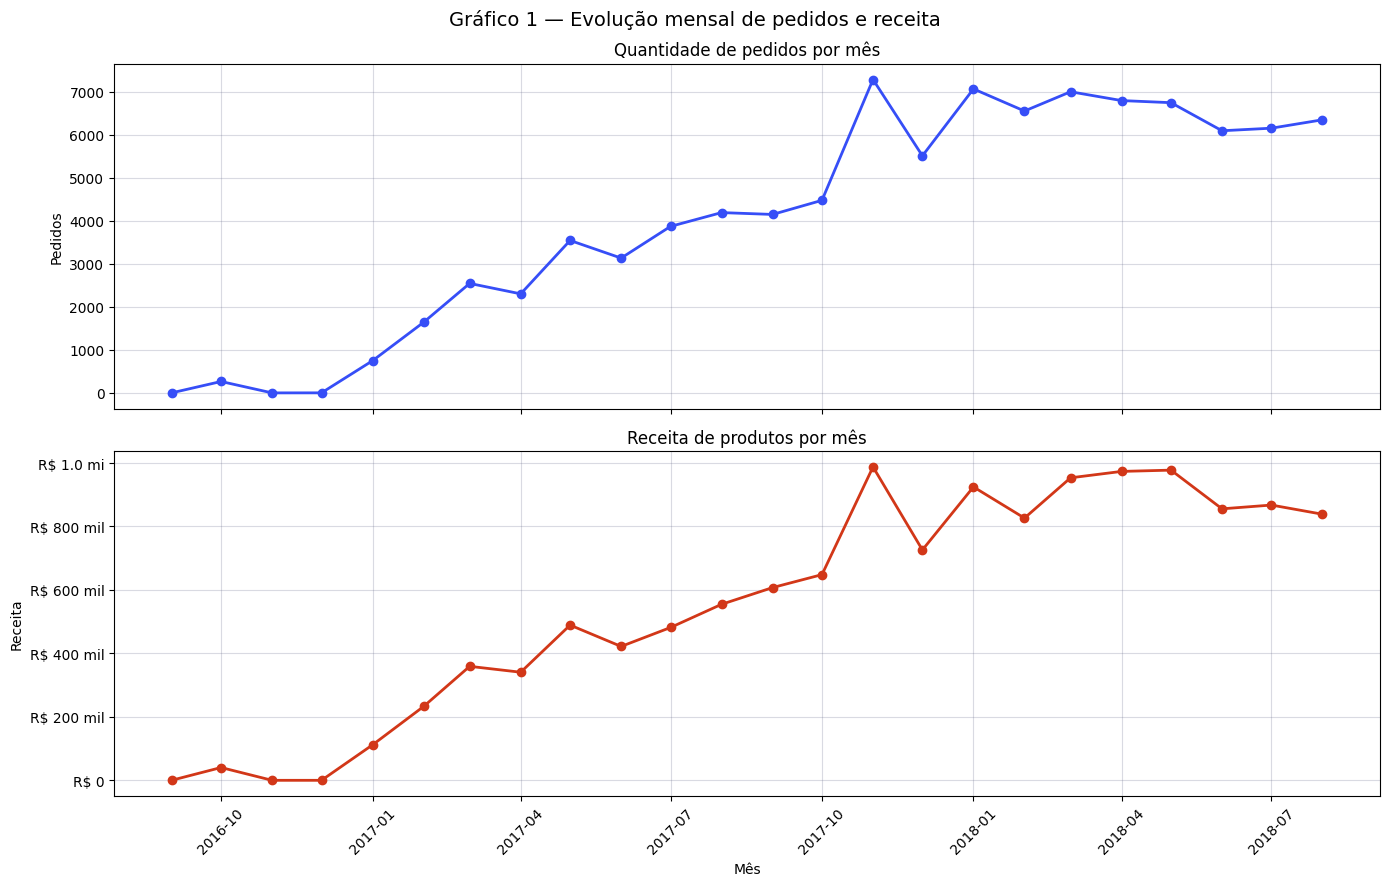

In [4]:
dados["mes"] = dados["order_purchase_timestamp"].dt.to_period("M")

mensal = (
    dados.groupby("mes")
    .agg(
        pedidos=("order_id", "nunique"),
        receita=("price", "sum")
    )
    .reset_index()
)

todos_meses = pd.period_range(
    mensal["mes"].min(),
    mensal["mes"].max(),
    freq="M"
)

mensal = (
    mensal.set_index("mes")
    .reindex(todos_meses)
    .rename_axis("mes")
    .reset_index()
)

mensal["pedidos"] = mensal["pedidos"].fillna(0).astype(int)
mensal["receita"] = mensal["receita"].fillna(0)
mensal["mes_data"] = mensal["mes"].dt.to_timestamp()

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

ax1.plot(
    mensal["mes_data"],
    mensal["pedidos"],
    marker="o",
    linewidth=2,
    color=COR_PRINCIPAL
)
ax1.set_title("Quantidade de pedidos por mês")
ax1.set_ylabel("Pedidos")
ax1.grid(alpha=0.25, color=COR_NEUTRA)

ax2.plot(
    mensal["mes_data"],
    mensal["receita"],
    marker="o",
    linewidth=2,
    color=COR_DESTAQUE
)
ax2.set_title("Receita de produtos por mês")
ax2.set_xlabel("Mês")
ax2.set_ylabel("Receita")
ax2.yaxis.set_major_formatter(FuncFormatter(reais_eixo))
ax2.grid(alpha=0.25, color=COR_NEUTRA)
ax2.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Gráfico 1 — Evolução mensal de pedidos e receita",
    fontsize=14
)

fig.tight_layout()
plt.savefig("grafico_1_pedidos_receita.png", dpi=180, bbox_inches="tight")
plt.show()

### Resultado usado no relatório

A partir de 2017, pedidos e receita passam a crescer de forma mais consistente.

Pontos de referência:

- janeiro de 2017: aproximadamente **748 pedidos**;
- maio de 2017: aproximadamente **3.545 pedidos**.

A receita acompanha esse crescimento.

## 3.1 Ticket médio

O ticket médio é calculado por:

**receita de produtos ÷ quantidade de pedidos**

Ele é usado como indicador de apoio para verificar se o crescimento veio do aumento do valor médio de cada compra ou do aumento da quantidade de pedidos.

In [5]:
dados["ano"] = dados["order_purchase_timestamp"].dt.year

ticket_anual = (
    dados[dados["ano"].isin([2017, 2018])]
    .groupby("ano")
    .agg(
        pedidos=("order_id", "nunique"),
        receita=("price", "sum")
    )
    .reset_index()
)

ticket_anual["ticket_medio"] = (
    ticket_anual["receita"] / ticket_anual["pedidos"]
)

display(ticket_anual.round(2))

,ano,pedidos,receita,ticket_medio
0,2017,43412,"5,960,935.28",137.31
1,2018,52777,"7,217,172.24",136.75


### Interpretação

O ticket médio permanece próximo de **R$ 137** em 2017 e 2018.

Assim, a principal interpretação é que o crescimento da receita veio principalmente do **aumento do volume de pedidos**.

> Observação: 2018 é um ano incompleto na base. O valor é usado aqui para observar o nível do ticket médio, e não para fazer uma comparação anual completa de crescimento.

# 4. Gráfico 2 — Top 10 categorias por receita

Para identificar as categorias:

1. junto os itens com a tabela de produtos pelo `product_id`;
2. uso o CSV de tradução para obter os nomes em inglês;
3. calculo pedidos, receita e preço médio dos itens por categoria.

**Preço médio do item não é ticket médio.**

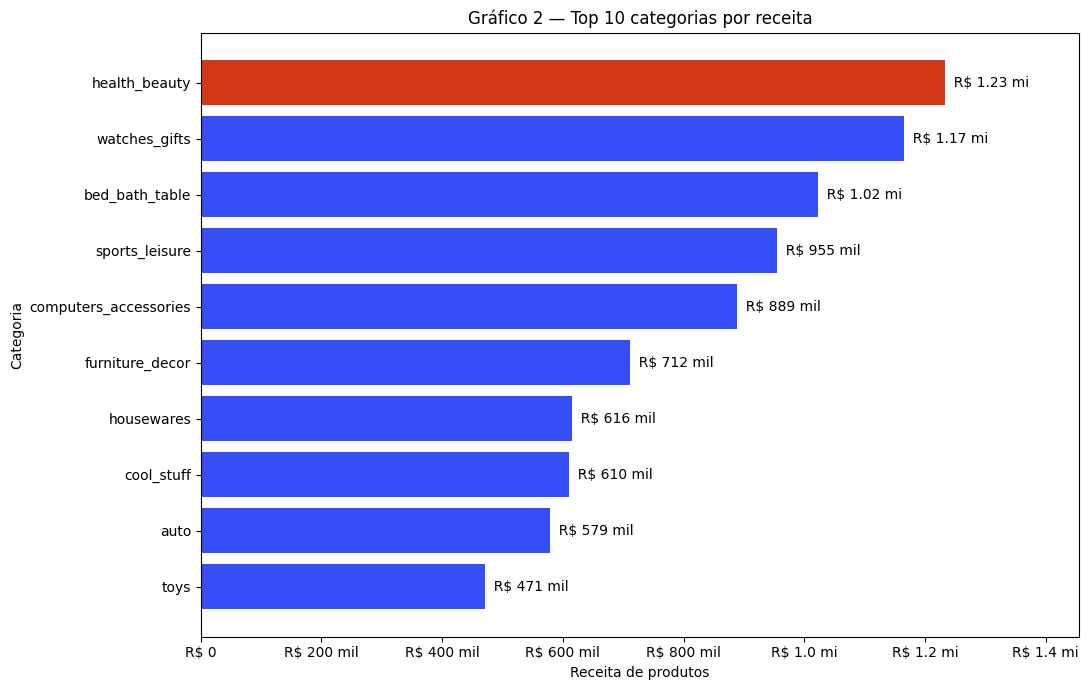

In [6]:
dados_cat = dados.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

dados_cat = dados_cat.merge(
    translation,
    on="product_category_name",
    how="left"
)

dados_cat["categoria"] = (
    dados_cat["product_category_name_english"]
    .fillna(dados_cat["product_category_name"])
    .fillna("sem_categoria")
)

categorias = (
    dados_cat.groupby("categoria")
    .agg(
        pedidos=("order_id", "nunique"),
        receita=("price", "sum"),
        preco_medio_item=("price", "mean")
    )
    .reset_index()
    .sort_values("receita", ascending=False)
)

top10 = categorias.head(10).sort_values("receita", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))

categoria_lider = categorias.iloc[0]["categoria"]
cores = [
    COR_DESTAQUE if categoria == categoria_lider else COR_PRINCIPAL
    for categoria in top10["categoria"]
]

barras = ax.barh(
    top10["categoria"],
    top10["receita"],
    color=cores
)

ax.set_title("Gráfico 2 — Top 10 categorias por receita")
ax.set_xlabel("Receita de produtos")
ax.set_ylabel("Categoria")
ax.xaxis.set_major_formatter(FuncFormatter(reais_eixo))

maior_receita_cat = top10["receita"].max()
ax.set_xlim(0, maior_receita_cat * 1.18)

for barra, valor in zip(barras, top10["receita"]):
    ax.text(
        barra.get_width(),
        barra.get_y() + barra.get_height()/2,
        f"  {reais_rotulo(valor)}",
        va="center"
    )

fig.tight_layout()
plt.savefig("grafico_2_categorias_receita.png", dpi=180, bbox_inches="tight")
plt.show()

## Tabela de apoio — categorias citadas no relatório

A tabela abaixo deixa explícita a diferença entre **pedidos**, **receita** e **preço médio do item**.

In [7]:
destaques_categoria = categorias[
    categorias["categoria"].isin([
        "health_beauty",
        "watches_gifts",
        "bed_bath_table"
    ])
][
    ["categoria", "pedidos", "receita", "preco_medio_item"]
].copy()

display(destaques_categoria.round(2))

,categoria,pedidos,receita,preco_medio_item
43,health_beauty,8647,"1,233,131.72",130.28
73,watches_gifts,5493,"1,165,898.98",199.06
7,bed_bath_table,9271,"1,023,300.77",93.44


### Resultado usado no relatório

- `health_beauty` lidera a receita, com aproximadamente **R$ 1,23 milhão**;

- `bed_bath_table` aparece em aproximadamente **9.271 pedidos**, com preço médio dos itens perto de **R$ 93**;

- `watches_gifts` aparece em menos pedidos, mas possui preço médio dos itens perto de **R$ 199** e receita próxima da liderança.

Isso sustenta a leitura de **volume x valor**.

# 5. Gráfico 3 — Receita e peso do frete por estado

A análise geográfica é dividida em dois painéis:

- **painel superior:** Top 10 estados por receita;
- **painel inferior:** Top 10 estados pelo percentual de frete sobre o valor dos produtos.

O percentual de frete é calculado por:

**frete total ÷ receita de produtos × 100**

No painel de frete, também mostro o número de pedidos para evitar interpretações erradas em estados com pouco volume.

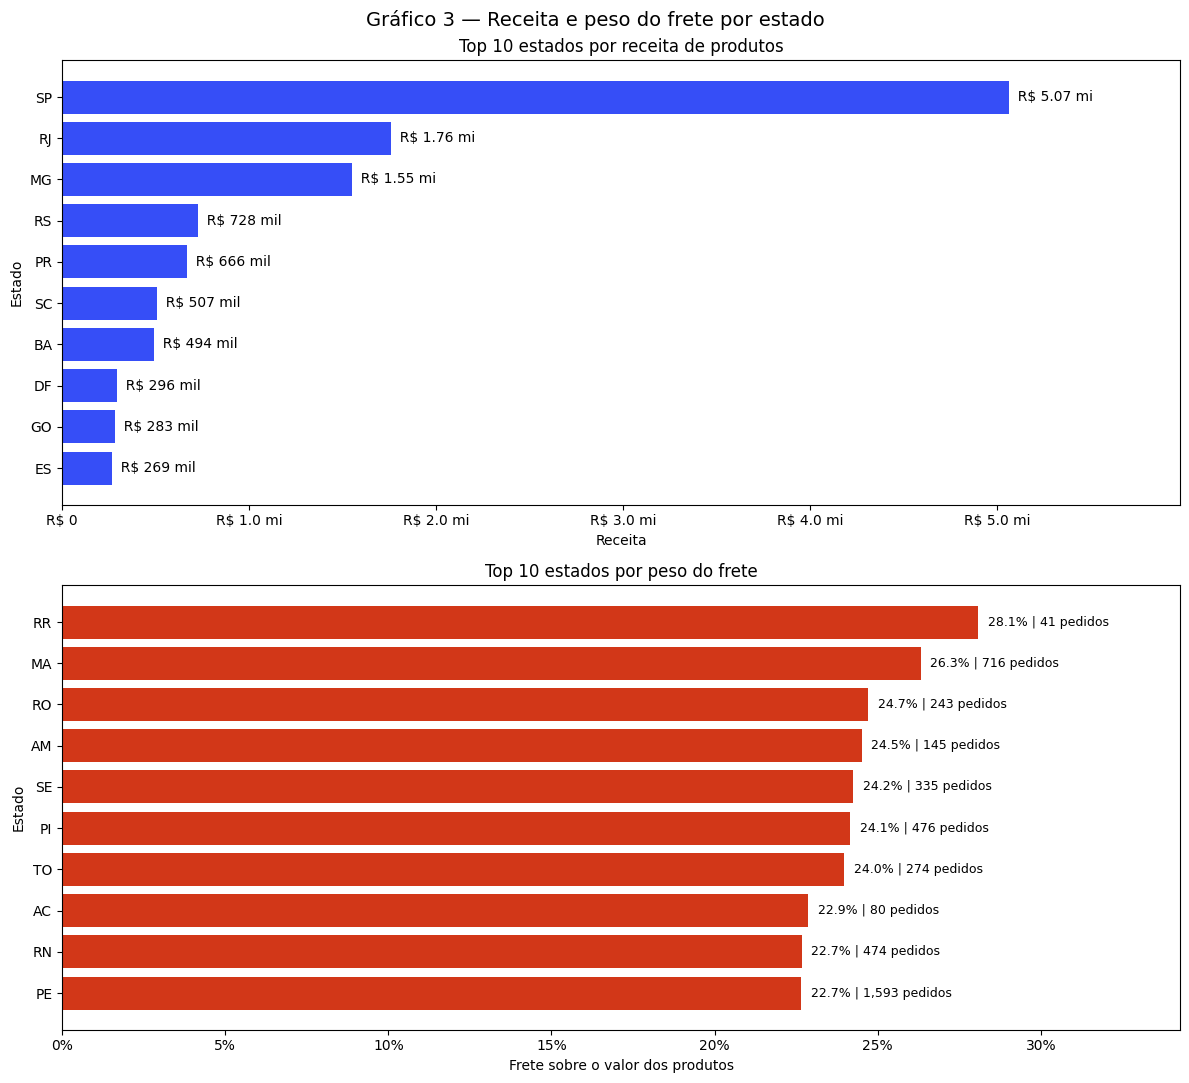

In [8]:
dados_uf = dados.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

estados = (
    dados_uf.groupby("customer_state")
    .agg(
        pedidos=("order_id", "nunique"),
        receita=("price", "sum"),
        frete=("freight_value", "sum")
    )
    .reset_index()
    .rename(columns={"customer_state": "uf"})
)

estados["frete_pct"] = (
    estados["frete"] / estados["receita"] * 100
)

top_receita = (
    estados.sort_values("receita", ascending=False)
    .head(10)
    .sort_values("receita", ascending=True)
)

top_frete = (
    estados.sort_values("frete_pct", ascending=False)
    .head(10)
    .sort_values("frete_pct", ascending=True)
)

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 11)
)

# Painel 1 — receita
b1 = ax1.barh(
    top_receita["uf"],
    top_receita["receita"],
    color=COR_PRINCIPAL
)

ax1.set_title("Top 10 estados por receita de produtos")
ax1.set_xlabel("Receita")
ax1.set_ylabel("Estado")
ax1.xaxis.set_major_formatter(FuncFormatter(reais_eixo))

maior_receita_uf = top_receita["receita"].max()
ax1.set_xlim(0, maior_receita_uf * 1.18)

for barra, valor in zip(b1, top_receita["receita"]):
    ax1.text(
        barra.get_width(),
        barra.get_y() + barra.get_height()/2,
        f"  {reais_rotulo(valor)}",
        va="center"
    )

# Painel 2 — frete
b2 = ax2.barh(
    top_frete["uf"],
    top_frete["frete_pct"],
    color=COR_DESTAQUE
)

ax2.set_title("Top 10 estados por peso do frete")
ax2.set_xlabel("Frete sobre o valor dos produtos")
ax2.set_ylabel("Estado")
ax2.xaxis.set_major_formatter(FuncFormatter(percentual))

maior_pct = top_frete["frete_pct"].max()
ax2.set_xlim(0, maior_pct * 1.22)

for barra, pct, pedidos in zip(
    b2,
    top_frete["frete_pct"],
    top_frete["pedidos"]
):
    ax2.text(
        barra.get_width() + 0.3,
        barra.get_y() + barra.get_height()/2,
        f"{pct:.1f}% | {int(pedidos):,} pedidos",
        va="center",
        fontsize=9
    )

fig.suptitle(
    "Gráfico 3 — Receita e peso do frete por estado",
    fontsize=14
)

fig.tight_layout()
plt.savefig("grafico_3_receita_frete_estado.png", dpi=180, bbox_inches="tight")
plt.show()

## Tabela de conferência — estados citados no relatório

In [9]:
display(
    estados[
        estados["uf"].isin(["SP", "RJ", "RR"])
    ][
        ["uf", "pedidos", "receita", "frete", "frete_pct"]
    ]
    .sort_values("receita", ascending=False)
    .round(2)
)

,uf,pedidos,receita,frete,frete_pct
25,SP,40489,"5,065,984.31","701,861.50",13.85
18,RJ,12348,"1,759,473.14","295,705.63",16.81
21,RR,41,"7,057.47","1,982.05",28.08


### Resultado usado no relatório

- São Paulo: aproximadamente **R$ 5,06 milhões** em receita;

- Rio de Janeiro: aproximadamente **R$ 1,76 milhão**;

- peso do frete em São Paulo: aproximadamente **13,85%**;

- peso do frete em Roraima: aproximadamente **28,08%**;

- Roraima possui apenas cerca de **41 pedidos**, portanto o percentual deve ser interpretado junto com o volume.

A investigação das causas logísticas pertence à parte de **Logística e SLA** do grupo.

# 6. Conclusão da documentação

Este notebook registra o código que sustenta os números e gráficos apresentados no relatório.

A principal leitura da minha parte é:

> **Mais pedidos → mais receita → ticket médio praticamente estável.**
